# Prévoir l'intérêt pour la « data science » avec Prophet

Ce projet prévoit l'intérêt de recherche Google pour le mot-clé « data science » aux États-Unis (Google Trends, données mensuelles de 2004 à 2020), avec la bibliothèque **Prophet** de Meta (Facebook).

**Démarche :**

 * Exploration de la série (tendance, saisonnalité, choix additif ou multiplicatif)
* Modèles Prophet entraînés sur 2004-2017
* Evaluation sur 2018-2019
* Validation croisée temporelle
* Conclusion.

In [1]:
# Bibliothèques
import warnings
warnings.filterwarnings("ignore")
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

# Masque les messages techniques du moteur de Prophet (à placer après l'import de prophet)
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.WARNING)

## Importer les données

👇 Allez sur [trends.google.com](https://trends.google.com/trends/?geo=US) et récupérez le jeu de données représentant l'intérêt au fil du temps pour le mot-clé `data science` depuis 2004 aux États-Unis. Une fois le jeu de données obtenu, importez-le et affichez les premières lignes.

In [2]:
# Données Google Trends : intérêt mensuel pour « data science » aux États-Unis (échelle 0-100)
df = pd.read_csv("data_science_google_trends.csv")
df.head()

,Month,data science: (United States)
0,2004-01,17
1,2004-02,13
2,2004-03,11
3,2004-04,6
4,2004-05,6


## Afficher les données

 Visualisez les données en affichant les premières lignes du DataFrame.

In [3]:
# Types des colonnes, valeurs manquantes et dernières lignes
df.info()
display(df.tail())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Month                          200 non-null    object
 1   data science: (United States)  200 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 3.3+ KB


,Month,data science: (United States)
195,2020-04,82
196,2020-05,80
197,2020-06,78
198,2020-07,77
199,2020-08,62


Le jeu de données contient 200 mois (janvier 2004 – août 2020), sans valeur manquante : la colonne Month (texte, au format AAAA-MM) et l'intérêt de recherche pour « data science » aux États-Unis, sur une échelle de 0 à 100 (100 = mois de plus forte popularité).

## Prétraitement des données

La bibliothèque Prophet de Facebook exige que les données soient dans un format précis.

 Mettez le jeu de données au format attendu par Prophet.
Rappel : le DataFrame doit contenir une colonne `ds` et une colonne `y`.

In [4]:
df.columns = ["ds", "y"]                   # noms de colonnes imposés par Prophet
df["ds"] = pd.to_datetime(df["ds"])        # texte "2004-01" -> date 2004-01-01

# Août 2020 est incomplet (extraction en cours de mois) : on le retire
df = df[df["ds"] < "2020-08-01"].reset_index(drop=True)

print(f"{len(df)} mois : {df['ds'].min():%Y-%m} -> {df['ds'].max():%Y-%m}")
display(df.head())

199 mois : 2004-01 -> 2020-07


,ds,y
0,2004-01-01,17
1,2004-02-01,13
2,2004-03-01,11
3,2004-04-01,6
4,2004-05-01,6


## Tracer les données

👇 Tracez les données.

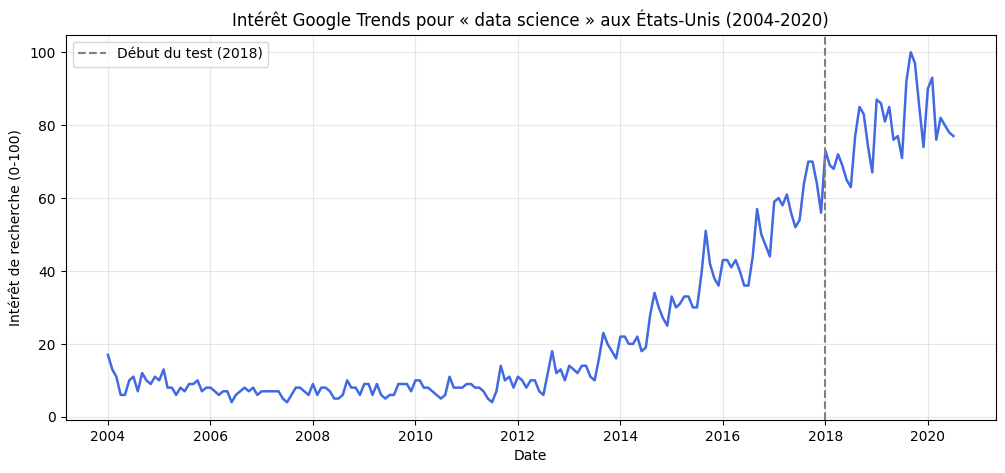

In [5]:
# Visualisation de la série temporelle
plt.figure(figsize=(12, 5))

# Courbe de l'intérêt de recherche (y) en fonction de la date (ds)
plt.plot(df["ds"], df["y"], color="royalblue", linewidth=1.8)

# Ligne verticale pointillée : séparation entre entraînement (avant 2018) et test (à partir de 2018)
plt.axvline(pd.Timestamp("2018-01-01"), color="grey", ls="--", label="Début du test (2018)")
plt.title("Intérêt Google Trends pour « data science » aux États-Unis (2004-2020)")
plt.xlabel("Date")
plt.ylabel("Intérêt de recherche (0-100)")
plt.legend()
plt.grid(alpha=0.3)

# Affichage du graphique
plt.show()

La série se décompose en trois phases :

- un intérêt faible et stable de 2004 à 2011 (entre 5 et 12),

- une forte croissance de 2012 à 2019 jusqu'au maximum de 100 en septembre 2019,

- puis un plafonnement en 2020, marqué par une chute en mars (93 → 76) au début de la crise du Covid. Une saisonnalité annuelle apparaît nettement : pic à la rentrée universitaire (septembre), creux en été et en décembre.

Son amplitude augmente avec le niveau de la série (quelques points avant 2012, plus de 20 points en 2019), ce qui suggère une saisonnalité multiplicative.

## Le profil saisonnier par mois

Objectif : confirmer quels mois sont hauts ou bas, et vérifier que ce profil se répète chaque année.

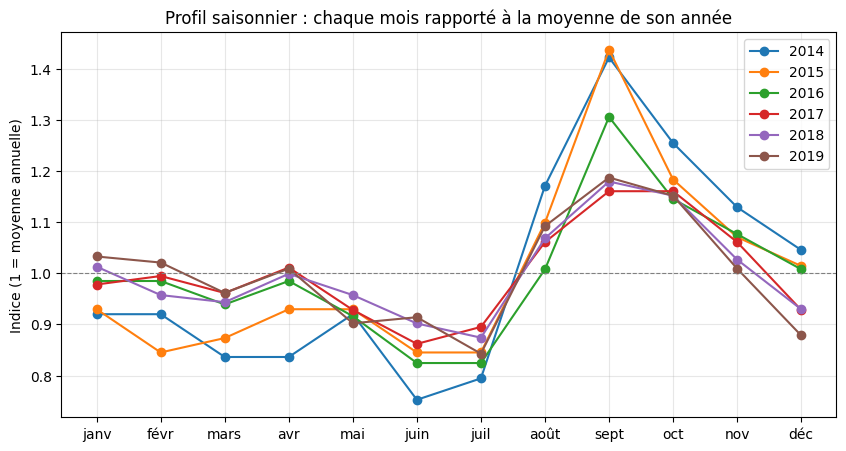

In [6]:
# Mois (1 à 12) et année extraits de la date, pour comparer les années entre elles

df["mois"] = df["ds"].dt.month
df["annee"] = df["ds"].dt.year

# On se limite à la période de croissance (2014-2019), où la saisonnalité est nette

recent = df[(df["annee"] >= 2014) & (df["annee"] <= 2019)].reset_index(drop=True)

# Pour comparer des années de niveaux différents, on divise chaque mois par la moyenne de son année (normalisation)
recent = recent.assign(indice=recent.groupby("annee")["y"].transform(lambda x: x / x.mean()))

# Une courbe par année : si elles se superposent, la saisonnalité est stable
plt.figure(figsize=(10, 5))
for annee, g in recent.groupby("annee"):
    plt.plot(g["mois"], g["indice"], marker="o", label=annee)
plt.axhline(1, color="grey", ls="--", lw=0.8)          # 1 = niveau moyen de l'année
plt.xticks(range(1, 13), ["janv", "févr", "mars", "avr", "mai", "juin",
                          "juil", "août", "sept", "oct", "nov", "déc"])
plt.title("Profil saisonnier : chaque mois rapporté à la moyenne de son année")
plt.ylabel("Indice (1 = moyenne annuelle)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

Le profil saisonnier se répète chaque année : intérêt proche de la moyenne de janvier à mai, creux en juin-juillet (vacances d'été), forte hausse en août et pic en septembre (rentrée universitaire), puis baisse jusqu'en décembre.

 En proportion, le pic de septembre s'atténue au fil des années (+43 % au-dessus de la moyenne annuelle en 2014-2015, +17 % en 2017-2019), alors que son amplitude en points augmente.

 La saisonnalité se situe donc entre un modèle additif et un modèle multiplicatif : les deux seront testés.

## La décomposition (additive ou multiplicative)

Objectif : séparer la tendance, la saisonnalité et le bruit, et voir quel mode convient le mieux.

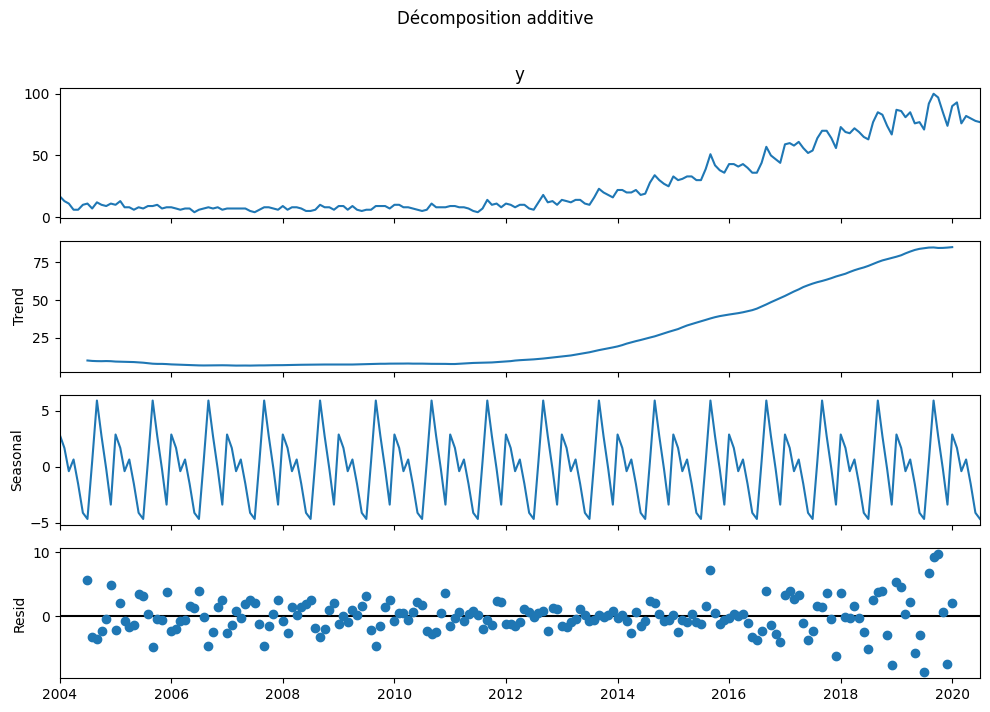

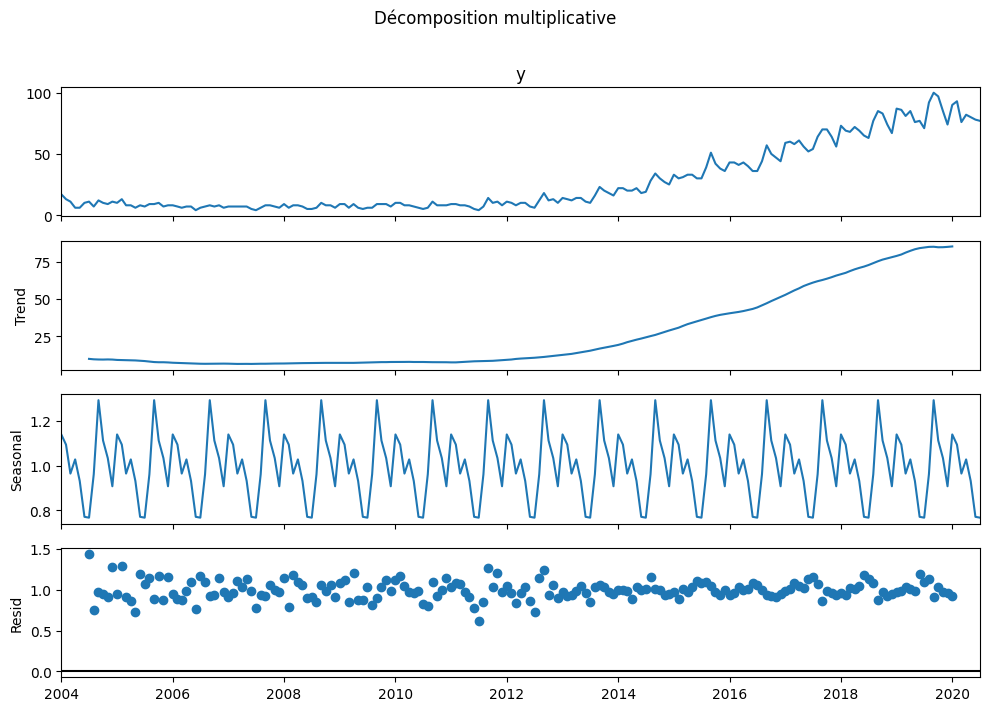

In [7]:

# Série indexée par date, comme l'exige seasonal_decompose ; période de 12 mois
serie = df.set_index("ds")["y"]

for mode in ["additive", "multiplicative"]:
    decomp = seasonal_decompose(serie, model=mode, period=12)
    fig = decomp.plot()
    fig.set_size_inches(10, 7)
    fig.suptitle(f"Décomposition {mode}", y=1.01)
    plt.tight_layout()
    plt.show()

Les deux décompositions font apparaître la même tendance en S : stable jusqu'en 2012, forte croissance ensuite, puis un plateau autour de 85 en 2019-2020, ce qui suggère qu'une croissance logistique pourrait convenir.

- Dans la décomposition additive, la saisonnalité est fixe (−5 à +6 points) et les résidus grandissent nettement à partir de 2017 : ce mode sous-estime les variations saisonnières quand le niveau augmente.

 - Dans la décomposition multiplicative, la saisonnalité est un coefficient (de 0,77 en été à 1,30 en septembre) et les résidus sont réguliers sur la période de croissance, mais plus dispersés avant 2012, où les faibles valeurs rendent les écarts relatifs importants.

- Le mode multiplicatif semble mieux adapté à la période récente ; les deux seront comparés sur le jeu de test.

## L’effet du logarithme

Objectif : vérifier si le log rend l’amplitude saisonnière constante. Si oui, un modèle additif sur log(y) revient à un modèle multiplicatif sur y.

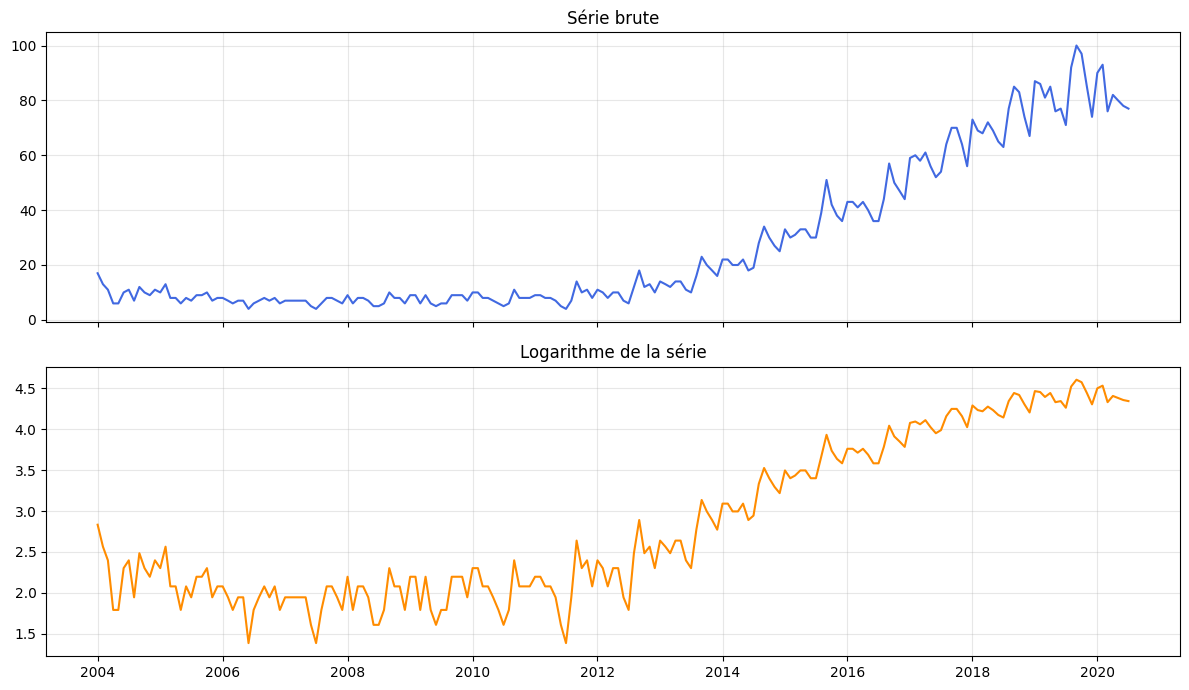

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Série brute : l'amplitude des variations grandit avec le niveau
axes[0].plot(df["ds"], df["y"], color="royalblue")
axes[0].set_title("Série brute")

# Série en log : si l'amplitude devient constante, la saisonnalité est multiplicative
axes[1].plot(df["ds"], np.log(df["y"]), color="darkorange")
axes[1].set_title("Logarithme de la série")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Le logarithme ne rend pas l'amplitude constante : les variations restent fortes avant 2012 (±0,4 à 0,5, sur des valeurs faibles et bruitées) et deviennent faibles après 2017 (±0,15 à 0,2).
La saisonnalité n'est donc pas purement multiplicative. La tendance en log est quasi linéaire de 2012 à 2017 (croissance exponentielle à taux constant), puis ralentit à partir de 2018 : la popularité du terme approche d'un plafond.

Ces analyses conduisent à comparer les modes additif et multiplicatif de Prophet, et à envisager une croissance logistique.

## Ajuster le modèle

👇 Ajustez un modèle sur les données avec la bibliothèque Prophet de Facebook. Pensez à faire une séparation entraînement/test (train/test split).

In [9]:

# Séparation entraînement / test dans l'ordre du temps (jamais au hasard)
# On ne garde que ds et y : Prophet n'accepte pas d'autres colonnes non déclarées (mois, annee)
train = df.loc[df["ds"] < "2018-01-01", ["ds", "y"]]                                  # 2004-2017
test = df.loc[(df["ds"] >= "2018-01-01") & (df["ds"] < "2020-01-01"), ["ds", "y"]]   # 2018-2019

# Modèle 1 : saisonnalité additive (réglage par défaut de Prophet)
# Données mensuelles : saisonnalités hebdomadaire et journalière désactivées, elles n'ont pas de sens ici
model_add = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
model_add.fit(train)

print(f"Entraînement : {len(train)} mois ({train['ds'].min():%Y-%m} -> {train['ds'].max():%Y-%m})")
print(f"Test : {len(test)} mois ({test['ds'].min():%Y-%m} -> {test['ds'].max():%Y-%m})")

Entraînement : 168 mois (2004-01 -> 2017-12)
Test : 24 mois (2018-01 -> 2019-12)


Le jeu de données est séparé dans l'ordre du temps : 168 mois d'entraînement (2004-2017) et 24 mois de test (2018-2019), soit les 2 ans à prévoir demandés par l'énoncé.

 Un premier modèle Prophet à saisonnalité additive (réglage par défaut) est ajusté sur l'entraînement. Les saisonnalités hebdomadaire et journalière sont désactivées, car les données sont mensuelles.

## Faire des prédictions futures

👇 Avant de prédire des valeurs futures avec Prophet, il faut d'abord créer un DataFrame « vide » qui contiendra les prédictions. Une fois ce DataFrame créé, essayez de prédire 2 ans dans le futur.

Vous pouvez créer le DataFrame des prédictions avec `make_future_dataframe()`.

In [10]:
# DataFrame des dates à prévoir : les 168 mois d'entraînement + 24 mois futurs (2 ans)
# freq="MS" (Month Start) : dates au 1er du mois, comme dans nos données
future = model_add.make_future_dataframe(periods=24, freq="MS")

print(f"{len(future)} dates : {future['ds'].min():%Y-%m} -> {future['ds'].max():%Y-%m}")
display(future.tail())

192 dates : 2004-01 -> 2019-12


,ds
187,2019-08-01
188,2019-09-01
189,2019-10-01
190,2019-11-01
191,2019-12-01


In [11]:
# Prédiction : Prophet remplit le DataFrame avec la prévision et son intervalle d'incertitude
forecast_add = model_add.predict(future)

# Les 24 mois prévus (2018-2019) : prévision (yhat) et bornes de l'intervalle à 80 %
display(forecast_add[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(24))

,ds,yhat,yhat_lower,yhat_upper
168,2018-01-01,66.537401,63.590838,69.454395
169,2018-02-01,67.000748,64.159091,69.938256
170,2018-03-01,65.939215,62.993059,68.758154
171,2018-04-01,67.348015,64.471784,70.372629
172,2018-05-01,67.222987,64.443132,69.938340
173,2018-06-01,65.650986,62.884587,68.339491
174,2018-07-01,66.203514,63.263568,68.958665
175,2018-08-01,71.016252,68.409136,74.012526
176,2018-09-01,77.111864,74.126120,80.125012
177,2018-10-01,74.814844,71.583381,77.523515


## Tracer la prévision

👇 Il est temps de visualiser la prévision. Utilisez la fonction pratique [`model.plot(forecast)`](https://facebook.github.io/prophet/docs/quick_start.html).

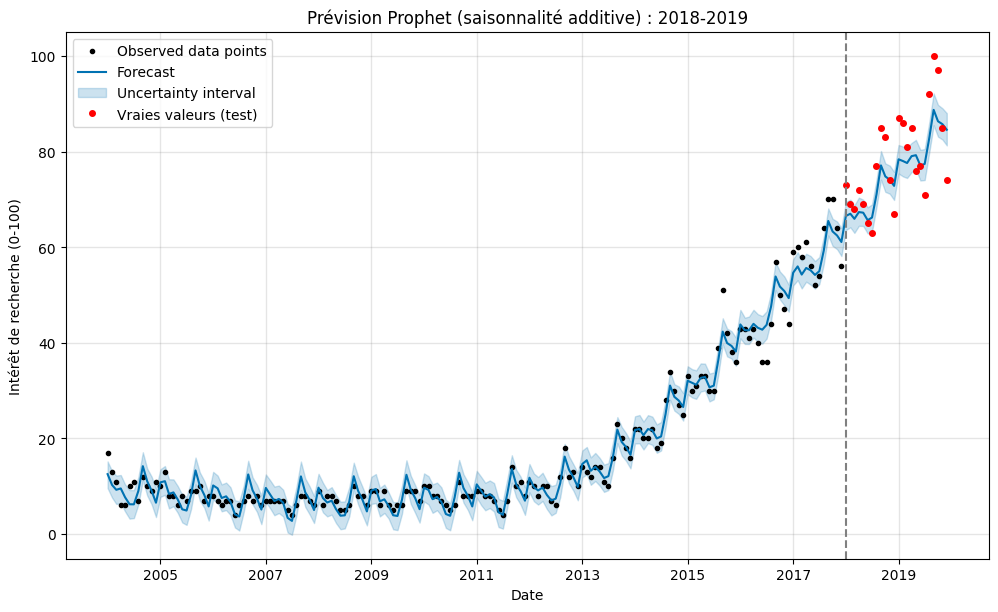

In [12]:
# Graphique de Prophet : points noirs = données d'entraînement, courbe bleue = prévision,
# zone bleu clair = intervalle d'incertitude à 80 %
fig = model_add.plot(forecast_add)
ax = fig.gca()

# Vraies valeurs de 2018-2019 (jeu de test) en rouge, pour comparer
ax.plot(test["ds"], test["y"], "r.", markersize=8, label="Vraies valeurs (test)")
ax.axvline(pd.Timestamp("2018-01-01"), color="grey", ls="--")    # début de la prévision

ax.set_title("Prévision Prophet (saisonnalité additive) : 2018-2019")
ax.set_xlabel("Date")
ax.set_ylabel("Intérêt de recherche (0-100)")
ax.legend()
plt.show()

De 2004 à fin 2017, les points noirs représentent les données d'entraînement ; de 2018 à 2019, la courbe bleue représente la prévision du modèle, et les points rouges les vraies valeurs du jeu de test. La zone bleu clair est l'intervalle d'incertitude à **80 %**, la valeur par défaut de Prophet (`interval_width=0.8`).

La prévision suit bien la tendance croissante, mais plusieurs points rouges sortent de l'intervalle, en particulier aux pics de septembre et de janvier : la saisonnalité du modèle additif est trop faible pour le niveau atteint en 2018-2019.

Le modèle suit bien la tendance (prévisions de 66 à 89 entre début 2018 et fin 2019), mais sa saisonnalité est trop faible : il sous-estime les pics de janvier et de la rentrée (77 prévu contre 85 réel en septembre 2018, 89 contre 100 en septembre 2019) et surestime les creux de juillet et décembre. Les erreurs augmentent en 2019, avec le niveau de la série.

### Calculer ces indicateurs avec le code

In [13]:
# Fonction d'évaluation : compare la prévision aux vraies valeurs du test
def evaluer(forecast, test):
    # On associe chaque mois du test à sa prévision, par la date
    m = test.merge(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]], on="ds")
    erreur = m["y"] - m["yhat"]
    return {
        "MAE": np.mean(np.abs(erreur)),                                    # erreur moyenne en points
        "RMSE": np.sqrt(np.mean(erreur ** 2)),                             # pénalise les grosses erreurs
        "MAPE (%)": 100 * np.mean(np.abs(erreur / m["y"])),                # erreur moyenne en %
        "Biais": np.mean(erreur),                                          # > 0 : le modèle sous-estime
        "Couverture IC 80 % (%)": 100 * np.mean((m["y"] >= m["yhat_lower"]) & (m["y"] <= m["yhat_upper"])),
    }

resultats = {"Prophet additif": evaluer(forecast_add, test)}
display(pd.DataFrame(resultats).T.round(2))

,MAE,RMSE,MAPE (%),Biais,Couverture IC 80 % (%)
Prophet additif,5.29,6.33,6.54,2.72,29.17


Le modèle additif obtient une MAE de 5,29 points et une MAPE de 6,54 % sur les 24 mois de test.

Le RMSE (6,33), plus élevé que la MAE, reflète quelques grosses erreurs aux pics de 2019. Le biais positif (+2,72) indique une sous-estimation moyenne du niveau.

Surtout, la couverture de l'intervalle à 80 % n'est que de 29 % : le modèle est trop confiant, son incertitude est largement sous-estimée.

### Modèle 2 : saisonnalité multiplicative

L'exploration a montré que l'amplitude saisonnière grandit avec le niveau de la série : on teste une saisonnalité multiplicative, exprimée en pourcentage de la tendance.

In [14]:
# Modèle 2 : saisonnalité multiplicative
# La saisonnalité devient un pourcentage de la tendance : son amplitude grandit avec le niveau
model_mult = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False,
                     seasonality_mode="multiplicative")
model_mult.fit(train)

# Même DataFrame de dates futures que pour le modèle additif (2 ans de prévision)
forecast_mult = model_mult.predict(future)

# Évaluation sur le même jeu de test, puis comparaison des deux modèles
resultats["Prophet multiplicatif"] = evaluer(forecast_mult, test)
display(pd.DataFrame(resultats).T.round(2))

,MAE,RMSE,MAPE (%),Biais,Couverture IC 80 % (%)
Prophet additif,5.29,6.33,6.54,2.72,29.17
Prophet multiplicatif,3.63,4.44,4.67,2.26,33.33


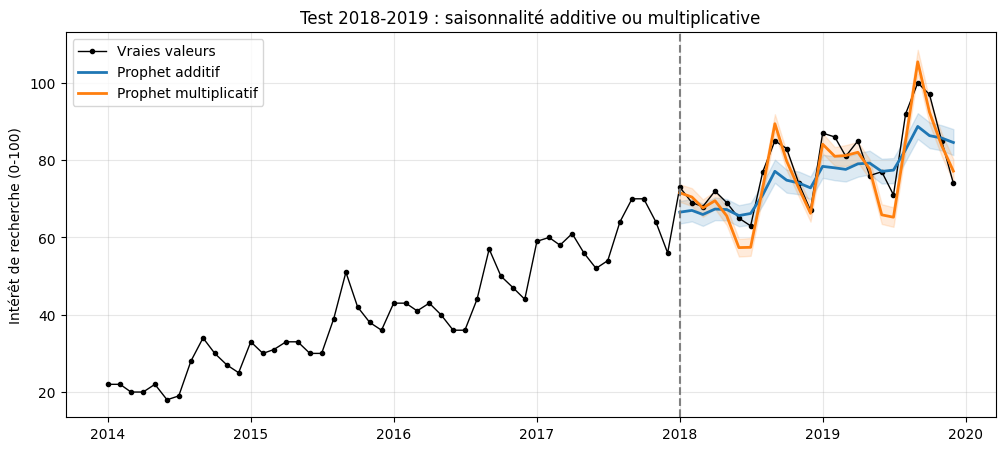

In [15]:
# Comparaison visuelle des deux modèles sur la période de test
fig, ax = plt.subplots(figsize=(12, 5))

# Vraies valeurs de 2014 à 2019 (fin de l'entraînement + test)
hist = df[(df["ds"] >= "2014-01-01") & (df["ds"] < "2020-01-01")]
ax.plot(hist["ds"], hist["y"], "k.-", lw=1, label="Vraies valeurs")

# Prévisions des deux modèles sur 2018-2019, avec leur intervalle à 80 %
for fc, nom, couleur in [(forecast_add, "additif", "tab:blue"), (forecast_mult, "multiplicatif", "tab:orange")]:
    f = fc[fc["ds"] >= "2018-01-01"]
    ax.plot(f["ds"], f["yhat"], color=couleur, lw=2, label=f"Prophet {nom}")
    ax.fill_between(f["ds"], f["yhat_lower"], f["yhat_upper"], color=couleur, alpha=0.15)

ax.axvline(pd.Timestamp("2018-01-01"), color="grey", ls="--")      # début du test
ax.set_title("Test 2018-2019 : saisonnalité additive ou multiplicative")
ax.set_ylabel("Intérêt de recherche (0-100)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Le modèle multiplicatif est nettement meilleur que le modèle additif sur les 24 mois de test : MAE de 3,63 contre 5,29 points (−31 %), RMSE de 4,44 contre 6,33, et MAPE de 4,67 % contre 6,54 %. En exprimant la saisonnalité en pourcentage de la tendance, il reproduit mieux l'amplitude des pics de rentrée et des creux d'été, qui grandit avec le niveau de la série, comme l'avait montré l'exploration.

Les deux modèles restent légèrement biaisés : ils sous-estiment le niveau d'environ 2 à 3 points en moyenne, car la croissance de 2018-2019 a été un peu plus rapide que la tendance apprise jusqu'en 2017.

Enfin, leurs intervalles d'incertitude sont trop étroits : seuls 29 % (additif) et 33 % (multiplicatif) des vraies valeurs tombent dans l'intervalle à 80 %. Prophet sous-estime son incertitude, car il ne tient compte que de l'incertitude sur la tendance et le bruit, pas de celle sur la saisonnalité. Ces intervalles sont donc à interpréter avec prudence.

On retient le modèle multiplicatif pour la suite.

## Tendance et saisonnalité de la série temporelle

👇 Tracez la tendance et la saisonnalité annuelle de la série. Vous pouvez utiliser la fonction `plot_components()` de la bibliothèque Prophet.

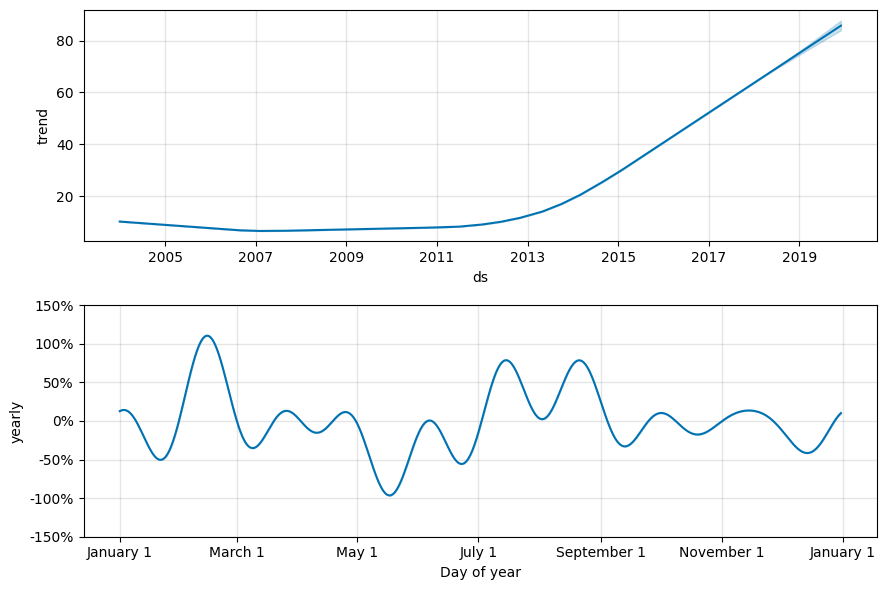

In [16]:
# Décomposition de la prévision du modèle multiplicatif (le meilleur) en ses composantes :
# - trend : la tendance de fond, avec ses changements de pente (changepoints)
# - yearly : la saisonnalité annuelle, en % de la tendance (mode multiplicatif)
fig = model_mult.plot_components(forecast_mult)

plt.show()

La tendance est stable jusqu'en 2011, décolle entre 2012 et 2015, puis croît de façon quasi linéaire (environ +11 points par an) ; Prophet prolonge cette pente sur 2018-2019 et ne peut pas anticiper le plafonnement observé en 2020.

La composante saisonnière présente de fortes oscillations (de −95 % à +110 %) qui ne sont pas réalistes : avec des données mensuelles, Prophet n'observe que 12 points par an, et sa courbe saisonnière continue (10 termes de Fourier par défaut) est libre d'osciller entre deux mois. Seules ses valeurs au 1er de chaque mois influencent la prévision. On teste donc une saisonnalité plus lisse, avec 4 termes de Fourier.

### Une saisonnalité plus lisse : 4 termes de Fourier

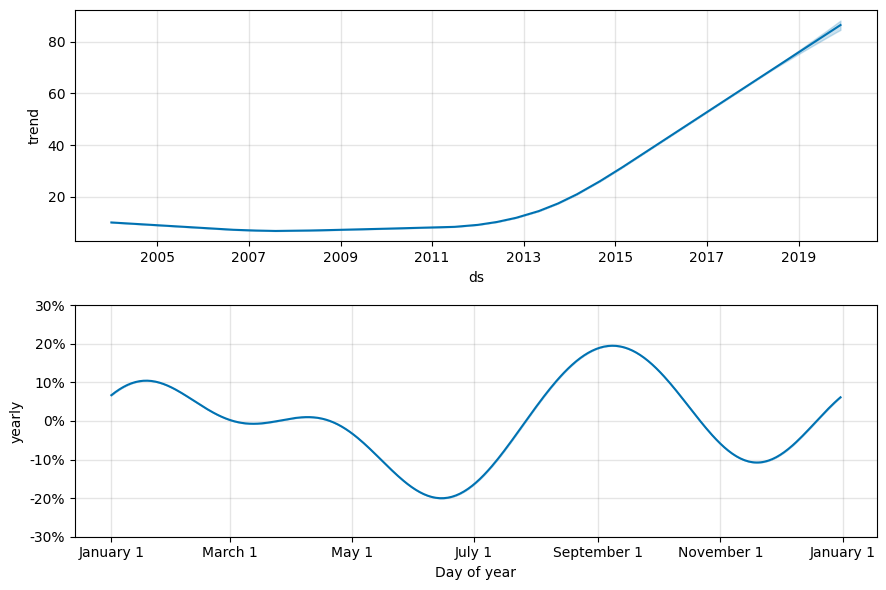

,MAE,RMSE,MAPE (%),Biais,Couverture IC 80 % (%)
Prophet additif,5.29,6.33,6.54,2.72,29.17
Prophet multiplicatif,3.63,4.44,4.67,2.26,33.33
Prophet multiplicatif (Fourier 4),3.63,4.38,4.77,2.81,33.33


In [17]:
# Saisonnalité annuelle plus lisse : 4 termes de Fourier au lieu de 10 (adapté à des données mensuelles)
model_mult4 = Prophet(yearly_seasonality=4, weekly_seasonality=False, daily_seasonality=False,
                      seasonality_mode="multiplicative")
model_mult4.fit(train)
forecast_mult4 = model_mult4.predict(future)

# Composantes : la courbe saisonnière devrait être lisse et interprétable
fig = model_mult4.plot_components(forecast_mult4)
plt.show()

# Comparaison des erreurs avec les modèles précédents
resultats["Prophet multiplicatif (Fourier 4)"] = evaluer(forecast_mult4, test)
display(pd.DataFrame(resultats).T.round(2))

Avec 4 termes de Fourier au lieu de 10, la saisonnalité annuelle devient lisse et interprétable : environ +10 % en janvier, proche de 0 % au printemps, un creux d'environ −20 % en juin-juillet (vacances d'été), un pic d'environ +20 % début septembre (rentrée universitaire) et environ −10 % en fin d'année. On retrouve le profil saisonnier observé lors de l'exploration, sans les oscillations irréalistes du modèle à 10 termes.

La précision est pratiquement inchangée (MAE de 3,63 dans les deux cas, MAPE de 4,77 % contre 4,67 %). Par parcimonie, on retient le modèle multiplicatif à 4 termes de Fourier : plus simple et plus facile à interpréter, pour des performances équivalentes.

La tendance, inchangée, croît de façon linéaire depuis 2015 : Prophet prolonge cette pente et ne pourra pas anticiper un éventuel plafonnement.

Pour comparaison, les composantes du modèle additif : sa saisonnalité s'exprime en points (et non en pourcentage), avec la même amplitude quel que soit le niveau de la série.

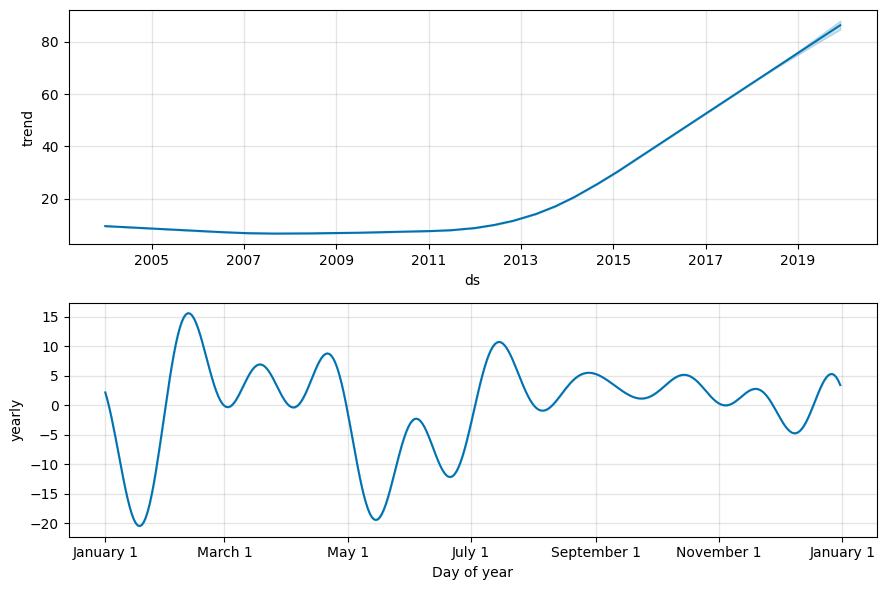

In [18]:
# Composantes du modèle additif, pour comparaison (saisonnalité en points)
fig = model_add.plot_components(forecast_add)
plt.show()

## Évaluer le modèle par validation croisée !

👇 Avec `cross_validation` et `performance_metrics` de [prophet.diagnostics](https://facebook.github.io/prophet/docs/diagnostics.html), évaluez la performance de votre modèle.
<img src='https://facebook.github.io/prophet/static/diagnostics_files/diagnostics_3_0.png'>

Plus précisément, créez une validation croisée temporelle en K plis (K-fold) avec :
- des jeux d'entraînement de 5 ans ;
- des horizons de validation de 1 an ;
- un décalage de 180 jours entre chaque pli.

In [19]:

# Validation croisée temporelle sur le modèle retenu (multiplicatif, Fourier 4),
# appliquée sur les données d'entraînement uniquement (2004-2017) :
# - initial  : 5 ans d'entraînement pour le premier pli
# - period   : on décale la date de coupure de 180 jours à chaque pli
# - horizon  : on prévoit 1 an après chaque date de coupure
df_cv = cross_validation(model_mult4, initial="1825 days", period="180 days", horizon="365 days")

# Métriques d'erreur moyennes, calculées selon l'horizon de prévision
df_p = performance_metrics(df_cv)
display(df_p[["horizon", "mae", "rmse", "mape", "coverage"]].head())
print("Nombre de plis :", df_cv["cutoff"].nunique())

  0%|          | 0/17 [00:00<?, ?it/s]

,horizon,mae,rmse,mape,coverage
0,41 days,2.149465,3.038914,0.122170,0.70
1,42 days,2.348144,3.215851,0.133453,0.65
2,46 days,2.558453,3.379648,0.140193,0.60
3,47 days,2.917517,3.918043,0.149658,0.55
4,48 days,2.837980,3.896064,0.142652,0.55


Nombre de plis : 17


**La validation croisée comporte 17 plis** : à chaque fois, le modèle est entraîné sur au moins 5 ans de données, puis prévoit l'année suivante, avec des dates de coupure de janvier 2009 à décembre 2016. À court terme (1 à 2 mois), l'erreur absolue est faible (MAE de 2 à 3 points).

 La MAPE (12 à 15 %) est plus élevée que sur le test 2018-2019, car les premiers plis portent sur des années où la série valait 5 à 15 : une erreur d'un ou deux points y représente un pourcentage important. La couverture de l'intervalle à 80 % (55 à 65 %) reste insuffisante : Prophet sous-estime son incertitude.

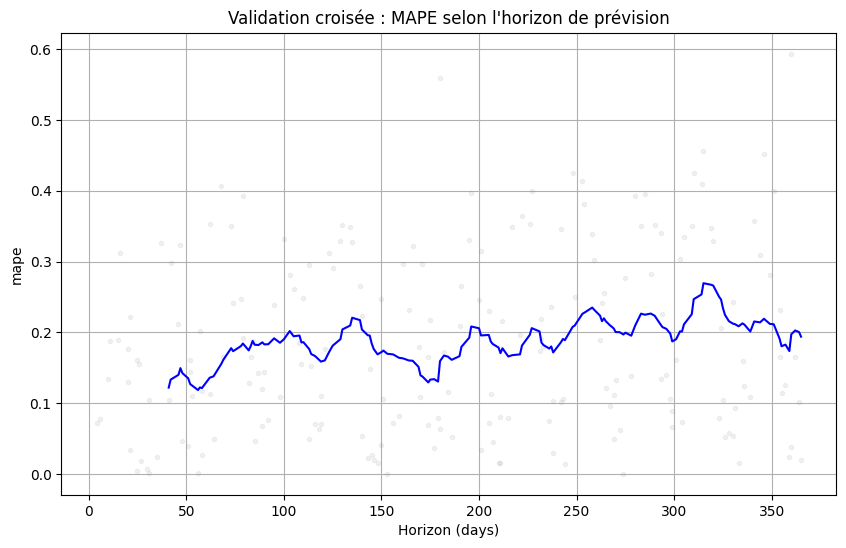

In [20]:
# Erreur relative (MAPE) selon l'horizon de prévision : chaque point est une prévision,
# la courbe bleue est la moyenne glissante
fig = plot_cross_validation_metric(df_cv, metric="mape")
plt.title("Validation croisée : MAPE selon l'horizon de prévision")
plt.show()

L'erreur de prévision augmente avec l'horizon : la MAPE moyenne passe d'environ 13 % à 1-2 mois à environ 20 % à 1 an, avec un maximum d'environ 27 % vers 10 mois.

 Cette hausse est attendue, car l'incertitude sur la tendance s'accumule avec le temps ; elle reste modérée, la saisonnalité étant régulière et bien prévue même à long terme. Les erreurs individuelles (points gris) sont très dispersées, de 0 à 60 % : les plus fortes viennent des premiers plis, où la série prenait des valeurs très faibles. Les oscillations de la moyenne s'expliquent par le petit nombre de plis (17).

### Comparaison des deux modèles en validation croisée

In [21]:
# Comparaison des modèles en validation croisée, avec une seule ligne de métriques par modèle
# (rolling_window=1 : moyenne sur tout l'horizon d'un an)
cv_resultats = {}
for nom, m in [("additif", model_add), ("multiplicatif (Fourier 4)", model_mult4)]:
    cv = cross_validation(m, initial="1825 days", period="180 days", horizon="365 days", disable_tqdm=True)
    cv_resultats[nom] = performance_metrics(cv, rolling_window=1)[["mae", "rmse", "mape", "coverage"]].iloc[0]

display(pd.DataFrame(cv_resultats).T.round(3))

,mae,rmse,mape,coverage
additif,3.873,5.152,0.179,0.389
multiplicatif (Fourier 4),3.880,5.043,0.184,0.399


En validation croisée (17 plis, 2009-2017), les deux modèles sont équivalents : MAE de 3,87 (additif) et 3,88 (multiplicatif), MAPE de 17,9 % et 18,4 %, couverture de 38 % et 40 %. Cette période comprend de nombreuses années où la série était faible : l'amplitude saisonnière y est de quelques points, et les deux modes donnent des prévisions proches. L'avantage du mode multiplicatif n'apparaît qu'à un niveau élevé, comme en 2018-2019 (MAE de 3,63 contre 5,29), où l'amplitude saisonnière grandit avec la tendance.

On retient donc le modèle multiplicatif à 4 termes de Fourier : aussi performant que l'additif sur l'ensemble de l'historique, nettement meilleur sur la période récente, la plus proche de celle à prévoir, et doté d'une saisonnalité interprétable.

## Conclusion

| Modèle | MAE test 2018-2019 | MAPE test | MAE validation croisée | MAPE validation croisée |
|---|---|---|---|---|
| Prophet additif | 5,29 | 6,54 % | 3,87 | 17,9 % |
| Prophet multiplicatif (Fourier 10) | 3,63 | 4,67 % | — | — |
| **Prophet multiplicatif (Fourier 4)** | **3,63** | **4,77 %** | **3,88** | **18,4 %** |

- La série « data science » (Google Trends, États-Unis) présente une tendance fortement croissante depuis 2012 et une saisonnalité annuelle marquée (pic à la rentrée de septembre, creux en été), dont l'amplitude grandit avec le niveau.
- Le modèle retenu est un Prophet à saisonnalité **multiplicative**, avec **4 termes de Fourier** : nettement meilleur que l'additif sur 2018-2019 (MAE de 3,63 contre 5,29), aussi bon sur l'ensemble de l'historique, et doté d'une saisonnalité lisse et interprétable.
- **Limites** : les intervalles d'incertitude de Prophet sont trop étroits (environ 35 à 40 % de couverture au lieu de 80 %), et la tendance linéaire ne peut pas anticiper un plafonnement de la popularité, comme celui observé en 2020.